In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from scipy.stats import t as t_dist
import io
import seaborn as sns
import os
from sklearn.feature_selection import mutual_info_regression

import warnings
warnings.filterwarnings('ignore')



path = str(os.getcwd())

plot_dir = f"{path}/plots"
os.makedirs(plot_dir, exist_ok=True)

The current PMAT grouping is: 
- AT: PERI, ORB, ECT, TEa, AI, PFC (IL+PL), OLF
- PM: VISpor, RSP, PAR, PRE, PTLp, VIS, POST

In [ ]:
# Load teh data
df_raw = pd.read_csv(path + '/master_detailed_comment.csv')

df_raw.columns = [str(c).strip() for c in df_raw.columns]

df = df_raw

# Remove neurons with no injection-defined projection classification
df['proj'] = df['proj'].replace('', np.nan).replace(r'^\s*$', np.nan, regex=True)
df = df.dropna(subset=['proj'])

# Clean soma coordinates
for c in ['x', 'y', 'z']:
    df[c] = pd.to_numeric(df[c], errors='coerce')
df = df.dropna(subset=['x', 'y', 'z'])

# Convert all axon length columns to numeric, fill missing with 0
for col in [c for c in df_raw.columns if c.endswith('_length')]:
    df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0)

# Define netwrok areas

AT_AREAS = [
    'PERI_length',   # perirhinal cortex
    'ORB_length',    # orbitofrontal cortex
    'AI_length',     # agranular insular cortex
    'OLF_length',    # olfactory cortex
    'TEa_length',    # temporal association cortex
    'ECT_length',    # ectorhinal cortex
    'PFC_length',    # mPFC (prelimbic + infralimbic)
   

]

# PM network — 9 areas
PM_AREAS = [
    'VISpor_length', # posteromedial visual cortex
    'RSP_length',    # retrosplenial cortex
    'PTLp_length',   # posterior parietal cortex
    'PAR_length',    # parasubiculum
    'POST_length',   # postsubiculum
    'PRE_length',    # presubiculum
    'VIS_length',    # primary visual cortex
    
]

# Subcortical targets to analyse
SUBCORT = [
    ('STRv_length', 'Ventral striatum (STRv)'),
    ('STRd_length', 'Dorsal striatum (STRd)'),
    ('BLA_length',  'Basolateral amygdala (BLA)'),
]

# Calculate netwrok bias score
# Bias = (PM − AT) / (PM + AT)   range: −1 (AT) to +1 (PM)
df['AT_sum']   = df[[c for c in AT_AREAS if c in df.columns]].sum(axis=1)
df['PM_sum']   = df[[c for c in PM_AREAS if c in df.columns]].sum(axis=1)
df['Total_neo']= df['AT_sum'] + df['PM_sum']
df['PMAT_Bias']= np.where(df['Total_neo'] > 0,
                           ( df['PM_sum'] - df['AT_sum'] ) / df['Total_neo'],
                           np.nan)

# Keep only neurons with neocortical projections
plot_df = df[df['Total_neo'] > 0].dropna(subset=['PMAT_Bias']).copy()

print(f"Number of neurons included in the analysis: {len(plot_df)}")

# distance from most mediolateral soma
z_distance    = plot_df['z'].values - plot_df['z'].min()     
z = z_distance
bias = plot_df['PMAT_Bias'].values


# PMAT bias regressed over mediolateral axis position — linear regression
slope, intercept, r, p, se = stats.linregress(z, bias)
rho_pmat, _ = stats.spearmanr(z, bias) # the package suggests using permutations for p-value calculations instead because of a small sample size (less than 500 observations)


# p-value with permutations for Pearson
def pearson_statistic(z): # permute only `x`
    return stats.pearsonr(z, bias).statistic
permutation_stats_pears = stats.permutation_test((z,), pearson_statistic,
    permutation_type='pairings')

# p-value with permutations for Spearman
def spearmanr_statistic(z): # permute only `x`
    return stats.spearmanr(z, bias).statistic
permutation_stats_spear = stats.permutation_test((z,), spearmanr_statistic,
    permutation_type='pairings')


# Print statistics
print(f"RSP (medial):        n = {(plot_df['proj']=='rsp').sum()}")
print(f"RSP+ORB (intermediate): n = {(plot_df['proj']=='rsp_orb').sum()}")
print(f"ORB (lateral):       n = {(plot_df['proj']=='orb').sum()}")
print(f"PMAT bias vs ML position:")
print(f"Spearman ρ = {rho_pmat:.3f},  p = {permutation_stats_spear.pvalue:.2e}")
print(f"Pearson r  = {r:.3f},  R² = {r**2:.3f},  p = {permutation_stats_pears.pvalue:.2e}")
print(f"Slope = {slope:.6f} bias units per µm")



Number of neurons included in the analysis: 160
RSP (medial):        n = 58
RSP+ORB (intermediate): n = 54
ORB (lateral):       n = 48
PMAT bias vs ML position:
Spearman ρ = -0.835,  p = 2.00e-04
Pearson r  = -0.840,  R² = 0.705,  p = 2.00e-04
Slope = -0.001674 bias units per µm


# Figure 6a plot - the mediolateral axis against soma projection bias, coloured based on projection bias 

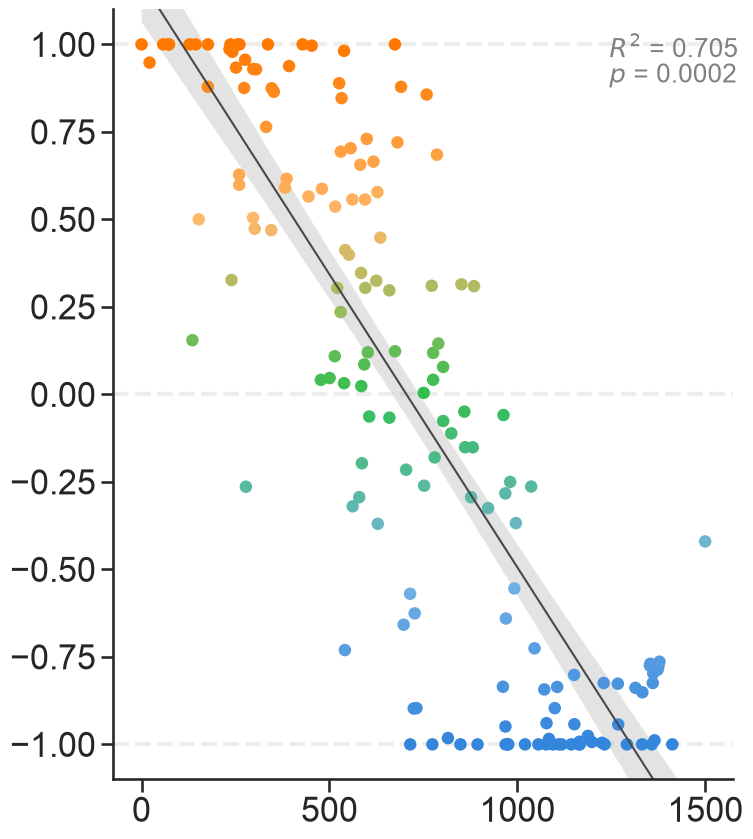

In [6]:



# Diverging colourmap: orange (AT, −1) → green (0) → blue (PM, +1)
cmap = LinearSegmentedColormap.from_list('ogb_bright', [
    ( 52/255, 133/255, 220/255),   # -1.0  AT
    (120/255, 180/255, 230/255),   # -0.5
    ( 50/255, 190/255,  80/255),   #  0.0
    (253/255, 185/255, 107/255),   # +0.5
    (255/255, 120/255,   0/255),   # +1.0  PM
])


sns.set_theme(font_scale=1.5, context="talk", style="white")
sns.set_style("ticks")

fig, ax = plt.subplots(figsize=(8, 10))

ax.axhline(y=-1, color='#EEEDED', linestyle='--', linewidth=3, zorder=0)
ax.axhline(y=0, color='#EEEDED', linestyle='--', linewidth=3, zorder=0)
ax.axhline(y=1, color='#EEEDED', linestyle='--', linewidth=3, zorder=0)

sns.regplot(x=z, y=bias, x_ci='ci', scatter=False, fit_reg=True, 
            line_kws={'color': "#484848", 'lw': 1.5}, ax=ax) # The confidence interval is estimated using a bootstrap in this package (defaults: ci=95, n_boot=1000)
sns.scatterplot(x=z, y=bias, hue=bias, palette=cmap, legend=False, 
                edgecolor='none', ax=ax)

sns.despine()

norm = plt.Normalize(-1, 1)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
#ax.figure.colorbar(sm, ax=ax)
ax.set_ylim(-1.1, 1.1)
def format_pvalue(p):
    exp = int(np.floor(np.log10(abs(p))))
    coef = p / 10**exp
    return rf'$p = {coef:.2f} \times 10^{{{exp}}}$'

ax.text(0.8, 0.97, rf'$R^2$ = {r**2:.3f}', transform=ax.transAxes,
        verticalalignment='top', fontsize=19, color='grey')
ax.text(0.8, 0.93, rf'$p$ = {permutation_stats_pears.pvalue:.4f}', transform=ax.transAxes,
        verticalalignment='top', fontsize=19, color='grey')

plt.savefig(path + "/plots/pmat_bias_vs_position_long.svg")

plt.show()

# Figure 6b plot - medilateral position of the somata against axon length in one of the selec subcortical regions

  Ventral striatum (STRv):  ρ = 0.688,  p = 2.00e-04,  MI = 0.368,  p = 2.00e-04
  Dorsal striatum (STRd):  ρ = 0.531,  p = 2.00e-04,  MI = 0.182,  p = 2.40e-03
  Basolateral amygdala (BLA):  ρ = 0.696,  p = 2.00e-04,  MI = 0.324,  p = 2.00e-04


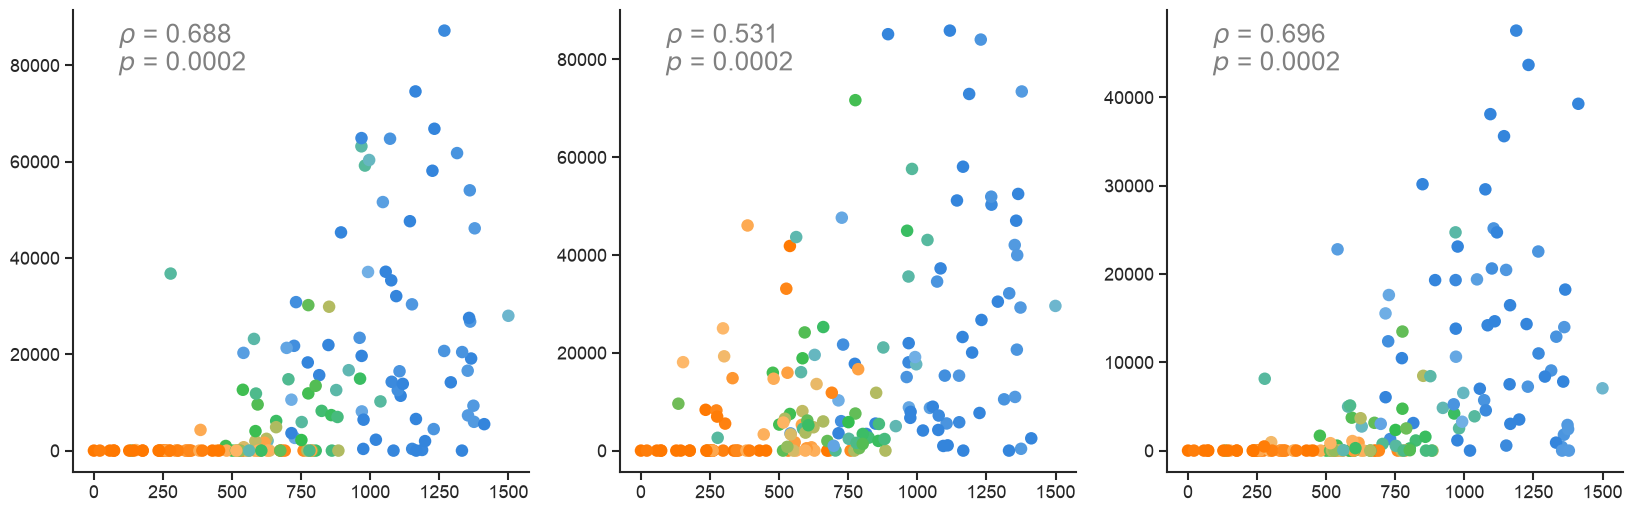

In [7]:



# Subcortical vs ML
SUBCORT = [
    ('STRv_length', 'Ventral striatum (STRv)'),
    ('STRd_length', 'Dorsal striatum (STRd)'),
    ('BLA_length',  'Basolateral amygdala (BLA)'),
]


sns.set_theme(font_scale=0.8, context="talk", style="white",
              rc={"axes.linewidth": 1.5,
                  "xtick.major.width": 1.5,
                  "ytick.major.width": 1.5,
                  "xtick.major.size": 6,
                  "ytick.major.size": 6})
sns.set_style("ticks")





fig, axes = plt.subplots(1, 3, figsize=(20, 6))



def mi_statistic(z, vals):
    return mutual_info_regression(np.asarray(z).reshape(-1, 1), vals, random_state=42)[0]

# p-value with permutations for Spearman
def spearmanr_statistic(z,vals): # permute only `x`
    return stats.spearmanr(z,vals).statistic


for i, (col, label) in enumerate(SUBCORT):
    if col in plot_df.columns:
        vals = plot_df[col].values
        rho, _ = stats.spearmanr(z, vals)
        permutation_stats_spear = stats.permutation_test((z,vals), spearmanr_statistic,
    permutation_type='pairings')
        mi = mutual_info_regression(z.reshape(-1, 1), vals, random_state=42)[0]
        permutation_stats_mi = stats.permutation_test((z, vals), mi_statistic,
                    permutation_type='pairings')
                
        print(f"  {label}:  ρ = {rho:.3f},  p = {permutation_stats_spear.pvalue:.2e},  MI = {mi:.3f},  p = {permutation_stats_mi.pvalue:.2e}")

        sns.scatterplot(x=z, y=vals, hue=bias, palette=cmap, legend=False, label=label,
                        edgecolor='none', ax=axes[i])
        
        axes[i].text(0.1, 0.97, rf'$ρ$ = {rho:.3f}', transform=axes[i].transAxes,
        verticalalignment='top', fontsize=19, color='grey')
        axes[i].text(0.1, 0.91, rf'$p$ = {permutation_stats_spear.pvalue:.4f}', transform=axes[i].transAxes,
        verticalalignment='top', fontsize=19, color='grey')
        
        


sns.despine()

plt.savefig(path + "/plots/subcortical_axon_length_vs_position.svg")
plt.show()

# Figure 6c - Plot of the binned soma across PMAT bias score against axon length to select areas for single neuron recostruction data

Single-neuron n = 160


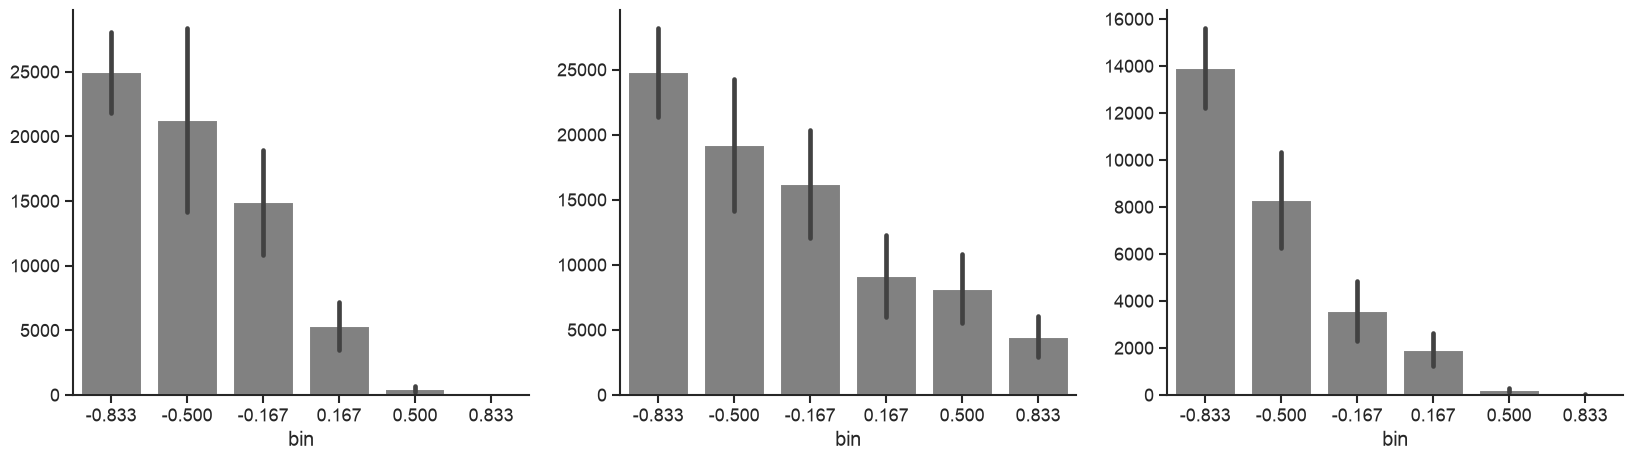

  bin sizes: bin
-0.833    52
-0.500     8
-0.167    20
0.167     23
0.500     20
0.833     37
dtype: int64
  STRv    : ρ =  -0.739,  p = 2.00e-04
  STRd    : ρ =  -0.537,  p = 2.00e-04
  BLA     : ρ =  -0.799,  p = 2.00e-04


In [5]:
# Load and organise the data
df_snr_raw    = pd.read_csv(path + '/master_detailed_comment.csv', encoding='latin-1')
df_snr_raw.columns = [str(c).strip() for c in df_snr_raw.columns]

snr_panels = [
    (plot_df['STRv_length'].values, 'STRv'),
    (plot_df['STRd_length'].values, 'STRd'),
    (plot_df['BLA_length'].values,  'BLA'),
]
print(f"Single-neuron n = {len(plot_df)}")




# Plot the data

COL_COLORS = ["#818181",   # dark grey   — STRv / vStr
              "#818181",   # mid grey    — STRd / dStr
              "#818181"]   # light grey  — BLA / OLF+CTXsp




sns.set_theme(font_scale=0.8, context="talk", style="white",
              rc={"axes.linewidth": 1.5,
                  "xtick.major.width": 1.5,
                  "ytick.major.width": 1.5,
                  "xtick.major.size": 6,
                  "ytick.major.size": 6})
sns.set_style("ticks")

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# Bin the data
plot_df['bin'] = pd.cut(plot_df['PMAT_Bias'], bins=6, labels=[f'{center:.3f}' for center in ((np.linspace(-1, 1, 7)[:-1] + np.linspace(-1, 1, 7)[1:]) / 2)])



for col_i, (vals, label) in enumerate(snr_panels):
    ax = axes[col_i]
    color = COL_COLORS[col_i]
    sns.barplot(x=plot_df['bin'], y=vals, width=0.8,
                   color=color, alpha=1, ax=ax, errorbar='se')
    # ax.set_title(label, fontsize=16, fontweight='bold')
    # ax.set_xlabel('PM/AT bias score bin')
    # ax.set_ylabel('Mean axon length (µm)')
    
sns.despine()

plt.savefig(path + "/plots/subcortical_axon_length_vs_bias_bined.svg")

plt.show()



# Print the summary stitastics

bin_sizes = plot_df.groupby('bin').size()
print(f"  bin sizes: {bin_sizes}")
for vals, label in snr_panels:
    permutation_stats_spear = stats.permutation_test((bias,vals), spearmanr_statistic, permutation_type='pairings')
    rho, _ = stats.spearmanr(bias, vals) # p-value not accurate at this sample size
    print(f"  {label:<8}: ρ = {rho:>7.3f},  p = {permutation_stats_spear.pvalue:.2e}")

# Figure 6d - Plot of the binned neuron across PMAT bias score against barcode counts to select areas for MAPseq data

MAPseq n = 4148


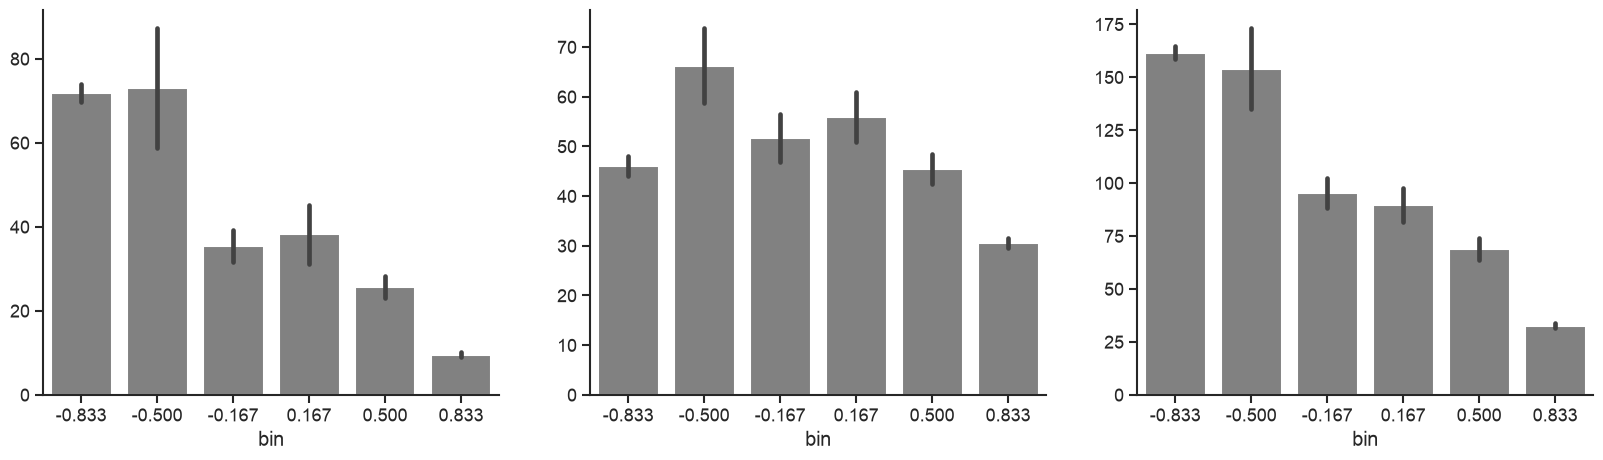

  bin sizes: bin
-0.833    1584
-0.500     123
-0.167     165
0.167      196
0.500      266
0.833     1814
dtype: int64
MAPseq — Spearman ρ (bias score vs barcode count):
  vStr          : ρ =  -0.627,  p = 2.00e-04
  dStr          : ρ =  -0.218,  p = 2.00e-04
  OLF + CTXsp*  : ρ =  -0.649,  p = 2.00e-04


In [6]:

# Load and organise the data
df_mapseq_raw = pd.read_csv(path + '/ec_mapseq_data_full.csv')

# These correspond to the statistically robust clusters
df_m = df_mapseq_raw.copy()

# Approximate PMAT bias score using available areas
# PM subset: RSC, PTL, VIS
# AT subset: ORB, PFC
PM_MAPSEQ = ['RSC', 'PTL']
AT_MAPSEQ = ['ORB', 'PFC']

df_m['PM_sum'] = df_m[PM_MAPSEQ].sum(axis=1)
df_m['AT_sum'] = df_m[AT_MAPSEQ].sum(axis=1)
df_m['Total']  = df_m['PM_sum'] + df_m['AT_sum']
df_m['Bias']   = np.where(df_m['Total'] > 0,
                           (-df_m['AT_sum'] + df_m['PM_sum']) / df_m['Total'],
                           np.nan)
df_m = df_m.dropna(subset=['Bias'])
df_m = df_m[df_m['Total'] > 0].copy()

m_bias   = df_m['Bias'].values
m_panels = [
    (df_m['vStr'].values, 'vStr'),
    (df_m['dStr'].values, 'dStr'),
    (df_m['OLF'].values,  'OLF + CTXsp*'),  # closest available to BLA
]
print(f"MAPseq n = {len(df_m)}")




# Plot the data
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# Bin the data
df_m['bin'] = pd.cut(df_m['Bias'], bins=6, labels=[f'{center:.3f}' for center in ((np.linspace(-1, 1, 7)[:-1] + np.linspace(-1, 1, 7)[1:]) / 2)])




for col_i, (vals, label) in enumerate(m_panels):
    ax = axes[col_i]
    color = COL_COLORS[col_i]
    sns.barplot(x=df_m['bin'], y=vals, width=0.8,
                   color=color, alpha=1, ax=ax, errorbar='se')
    # ax.set_title(label, fontsize=16, fontweight='bold')
    # ax.set_xlabel('PM/AT bias score bin')
    # ax.set_ylabel('Mean barcode count')
    
sns.despine()
# plt.subplots_adjust(wspace=0.3) 
plt.savefig(path + "/plots/mapseq_subcortical_barcode_count_vs_bias_bined.svg")
plt.show()



# Print the summary statistics

bin_sizes = df_m.groupby('bin').size()
print(f"  bin sizes: {bin_sizes}")
print("MAPseq — Spearman ρ (bias score vs barcode count):")
for vals, label in m_panels:
    permutation_stats_spear = stats.permutation_test((m_bias,vals), spearmanr_statistic, permutation_type='pairings')
    rho, _ = stats.spearmanr(m_bias, vals) # p-value not accurate at this sample size
    print(f"  {label:<14}: ρ = {rho:>7.3f},  p = {permutation_stats_spear.pvalue:.2e}")
